<a href="https://colab.research.google.com/github/print-tanish/-Mondrian-Project/blob/main/Dedup_prj.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 1. Mount
from google.colab import drive
drive.mount('/content/drive')

# 2. Locate the zip
!find /content/drive -iname "pnp_text_le.zip" 2>/dev/null

Mounted at /content/drive
/content/drive/MyDrive/Dedup_data/pnp_text_le.zip


In [ ]:
# STEP 0b — Extract the dataset from Drive into Colab's local storage
import zipfile, os

DRIVE_ZIP_PATH = "/content/drive/MyDrive/Dedup_data/pnp_text_le.zip"  # <-- adjust to your actual path
with zipfile.ZipFile(DRIVE_ZIP_PATH) as z:
    z.extractall(".")

print(os.listdir("."))
print(os.listdir("pnp_text_le"))   # should list version_0.txt ... version_9.txt

['.config', 'pnp_text_le', 'drive', 'sample_data']
['version_0.txt', 'version_2.txt', 'version_9.txt', 'version_3.txt', 'version_6.txt', 'version_7.txt', 'version_5.txt', 'version_8.txt', 'version_1.txt', 'version_4.txt']


In [ ]:
# STEP 1 — Load dataset and produce adaptive chunks
import os, hashlib, time, tracemalloc
import numpy as np
import pandas as pd

DATA_DIR = "pnp_text_le"

CDC_MIN_CHUNK, ENTROPY_WINDOW, ENTROPY_THRESHOLD = 2048, 1024, 4.5
CDC_MASK_LOW_BITS, CDC_MASK_HIGH_BITS = 12, 13
RANDOM_SEED = 42
_rng = np.random.RandomState(RANDOM_SEED)
GEAR = [int(x) for x in _rng.randint(0, 2**32 - 1, size=256, dtype=np.int64)]

def shannon_entropy(data):
    if not data: return 0.0
    counts = np.bincount(np.frombuffer(data, dtype=np.uint8), minlength=256)
    probs = counts[counts > 0] / len(data)
    return float(-np.sum(probs * np.log2(probs)))

def classify_entropy(h): return "low" if h < ENTROPY_THRESHOLD else "high"

def adaptive_chunk(data, entropy_window=ENTROPY_WINDOW):
    n = len(data)
    if n == 0: return []
    chunks, start, h, i = [], 0, 0, 0
    local_h = shannon_entropy(data[0:entropy_window])
    mask = (1 << (CDC_MASK_LOW_BITS if classify_entropy(local_h)=="low" else CDC_MASK_HIGH_BITS)) - 1
    while i < n:
        h = ((h << 1) + GEAR[data[i]]) & 0xFFFFFFFF
        i += 1
        chunk_len = i - start
        if chunk_len >= CDC_MIN_CHUNK and (h & mask) == 0:
            chunks.append(data[start:i]); start = i
            local_h = shannon_entropy(data[i:i+entropy_window])
            mask = (1 << (CDC_MASK_LOW_BITS if classify_entropy(local_h)=="low" else CDC_MASK_HIGH_BITS)) - 1
        elif chunk_len >= 16384:
            chunks.append(data[start:i]); start = i
    if start < n: chunks.append(data[start:n])
    return chunks

def read(p):
    with open(p, 'rb') as f: return f.read()

v0_data = read(os.path.join(DATA_DIR, "version_0.txt"))
v1_data = read(os.path.join(DATA_DIR, "version_1.txt"))
chunks_v0 = adaptive_chunk(v0_data)
chunks_v1 = adaptive_chunk(v1_data)
print(f"v0: {len(chunks_v0)} chunks, v1: {len(chunks_v1)} chunks")

v0: 79 chunks, v1: 79 chunks


In [ ]:
# STEP 2 — Ground-truth labeling for v0/v1 chunk pairs
import hashlib

def sha256_hash(data: bytes) -> str:
    return hashlib.sha256(data).hexdigest()

hashes_v0 = [sha256_hash(c) for c in chunks_v0]
hashes_v1 = [sha256_hash(c) for c in chunks_v1]

# We pair chunks positionally (index i in v0 <-> index i in v1). This is valid here
# because version_1 only inserts a couple of short lines relative to version_0 — the
# adaptive chunker's boundaries barely drift, so chunk counts stay equal (79 == 79)
# and index-i in one file corresponds to the same textual region in the other.
n_common = min(len(chunks_v0), len(chunks_v1))
assert len(chunks_v0) == len(chunks_v1), "Chunk counts differ — positional pairing won't hold, tell me before continuing."

ground_truth = []
for i in range(n_common):
    label = "identical" if hashes_v0[i] == hashes_v1[i] else "modified"
    ground_truth.append({
        "pair_index": i,
        "label": label,          # this is our TRUTH: is this pair actually the same content or not
        "v0_hash": hashes_v0[i],
        "v1_hash": hashes_v1[i],
        "v0_chunk": chunks_v0[i],
        "v1_chunk": chunks_v1[i],
    })

gt_df = pd.DataFrame(ground_truth)
print(gt_df["label"].value_counts())
gt_df[["pair_index", "label"]].head(10)

label
identical    77
modified      2
Name: count, dtype: int64


,pair_index,label
0,0,identical
1,1,identical
2,2,identical
3,3,identical
4,4,identical
5,5,identical
6,6,identical
7,7,identical
8,8,identical
9,9,identical


In [ ]:
# STEP 3 — Reusable evaluator + SHA-256 column
import time, tracemalloc

results_table = []   # one dict per algorithm gets appended here across the remaining steps

def evaluate_algorithm(name, predict_fn, gt_df):
    tracemalloc.start()
    t0 = time.perf_counter()
    predictions = []
    for _, row in gt_df.iterrows():
        pred = predict_fn(row["v0_chunk"], row["v1_chunk"])
        predictions.append(pred)
    elapsed = time.perf_counter() - t0
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    gt_df = gt_df.copy()
    gt_df[f"{name}_pred"] = predictions

    actual_dup = (gt_df["label"] == "identical")
    predicted_dup = pd.Series(predictions) == "duplicate"

    tp = int((actual_dup & predicted_dup).sum())
    fp = int((~actual_dup & predicted_dup).sum())
    fn = int((actual_dup & ~predicted_dup).sum())
    tn = int((~actual_dup & ~predicted_dup).sum())

    precision = tp / (tp + fp) if (tp + fp) else float("nan")
    recall = tp / (tp + fn) if (tp + fn) else float("nan")
    if (tp + fp) and (tp + fn) and (precision + recall):
        f1 = 2 * precision * recall / (precision + recall)
    else:
        f1 = float("nan")
    accuracy = (tp + tn) / len(gt_df) if len(gt_df) else float("nan")

    chunk_sizes = gt_df["v1_chunk"].apply(len)
    original_size = int(chunk_sizes.sum())
    data_transferred = int(chunk_sizes[~predicted_dup].sum())
    if data_transferred:
        dedup_ratio = original_size / data_transferred
    else:
        dedup_ratio = float("inf")

    if original_size:
        saved_pct = (1 - data_transferred / original_size) * 100
    else:
        saved_pct = 0

    row_result = {
        "Metric_col": name,
        "Similarity accuracy": round(accuracy, 3),
        "Precision": round(precision, 3),
        "Recall": round(recall, 3),
        "F1": round(f1, 3),
        "Processing time (s)": round(elapsed, 4),
        "Memory usage (KB)": round(peak / 1024, 1),
        "Duplicate chunks detected": int(predicted_dup.sum()),
        "Deduplication ratio": round(dedup_ratio, 2),
        "Storage saved (%)": round(saved_pct, 1),
        "Data transferred (bytes)": data_transferred,
        "Bandwidth saved (%)": round(saved_pct, 1),
    }
    return row_result, gt_df

def sha256_predict(v0_chunk, v1_chunk):
    if sha256_hash(v0_chunk) == sha256_hash(v1_chunk):
        return "duplicate"
    return "new"

sha_result, gt_df = evaluate_algorithm("SHA-256", sha256_predict, gt_df)
results_table.append(sha_result)
print(sha_result)

{'Metric_col': 'SHA-256', 'Similarity accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1': 1.0, 'Processing time (s)': 0.0719, 'Memory usage (KB)': 8.5, 'Duplicate chunks detected': 77, 'Deduplication ratio': 38.13, 'Storage saved (%)': 97.4, 'Data transferred (bytes)': 19740, 'Bandwidth saved (%)': 97.4}


In [ ]:
!pip install datasketch -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.2/107.2 kB 1.9 MB/s eta 0:00:00


In [ ]:
# STEP 4a — Add negative (unrelated) pairs + upgraded evaluator
import random
random.seed(42)

n_negatives = 20
neg_rows = []
used = set()
for _ in range(n_negatives):
    i = random.randrange(len(chunks_v0))
    j = random.randrange(len(chunks_v1))
    while j == i or (i, j) in used:
        j = random.randrange(len(chunks_v1))
    used.add((i, j))
    neg_rows.append({
        "pair_index": f"neg_{i}_{j}",
        "label": "unrelated",
        "v0_hash": hashes_v0[i],
        "v1_hash": hashes_v1[j],
        "v0_chunk": chunks_v0[i],
        "v1_chunk": chunks_v1[j],
    })
neg_df = pd.DataFrame(neg_rows)
eval_df = pd.concat(
    [gt_df[["pair_index", "label", "v0_hash", "v1_hash", "v0_chunk", "v1_chunk"]], neg_df],
    ignore_index=True
)
print(eval_df["label"].value_counts())

def evaluate_algorithm_v2(name, predict_fn, eval_df):
    tracemalloc.start()
    t0 = time.perf_counter()
    predictions = []
    for _, row in eval_df.iterrows():
        pred = predict_fn(row["v0_chunk"], row["v1_chunk"])
        predictions.append(pred)
    elapsed = time.perf_counter() - t0
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    eval_df = eval_df.copy()
    eval_df[f"{name}_pred"] = predictions

    actual_related = eval_df["label"].isin(["identical", "modified"])
    predicted_related = pd.Series(predictions) != "new"

    tp = int((actual_related & predicted_related).sum())
    fp = int((~actual_related & predicted_related).sum())
    fn = int((actual_related & ~predicted_related).sum())
    tn = int((~actual_related & ~predicted_related).sum())

    precision = tp / (tp + fp) if (tp + fp) else float("nan")
    recall = tp / (tp + fn) if (tp + fn) else float("nan")
    if (precision + recall):
        f1 = 2 * precision * recall / (precision + recall)
    else:
        f1 = float("nan")
    accuracy = (tp + tn) / len(eval_df) if len(eval_df) else float("nan")

    chunk_sizes = eval_df["v1_chunk"].apply(len)
    original_size = int(chunk_sizes.sum())
    data_transferred = int(chunk_sizes[predicted_related == False].sum())
    if data_transferred:
        dedup_ratio = original_size / data_transferred
    else:
        dedup_ratio = float("inf")
    saved_pct = (1 - data_transferred / original_size) * 100 if original_size else 0

    row_result = {
        "Metric_col": name,
        "Similarity accuracy": round(accuracy, 3),
        "Precision": round(precision, 3),
        "Recall": round(recall, 3),
        "F1": round(f1, 3),
        "Processing time (s)": round(elapsed, 4),
        "Memory usage (KB)": round(peak / 1024, 1),
        "Duplicate chunks detected": int(predicted_related.sum()),
        "Deduplication ratio": round(dedup_ratio, 2),
        "Storage saved (%)": round(saved_pct, 1),
        "Data transferred (bytes)": data_transferred,
        "Bandwidth saved (%)": round(saved_pct, 1),
    }
    return row_result, eval_df

def sha256_predict2(v0_chunk, v1_chunk):
    if sha256_hash(v0_chunk) == sha256_hash(v1_chunk):
        return "duplicate"
    return "new"

results_table2 = []
sha_result2, eval_df = evaluate_algorithm_v2("SHA-256", sha256_predict2, eval_df)
results_table2.append(sha_result2)
print(sha_result2)

label
identical    77
unrelated    20
modified      2
Name: count, dtype: int64
{'Metric_col': 'SHA-256', 'Similarity accuracy': 0.98, 'Precision': 1.0, 'Recall': 0.975, 'F1': 0.987, 'Processing time (s)': 0.0415, 'Memory usage (KB)': 10.7, 'Duplicate chunks detected': 77, 'Deduplication ratio': 4.51, 'Storage saved (%)': 77.8, 'Data transferred (bytes)': 209023, 'Bandwidth saved (%)': 77.8}


In [ ]:
# STEP 4 — MinHash + LSH column
from datasketch import MinHash   # pip install datasketch  (add a cell above if missing)

SHINGLE_SIZE = 5              # words per shingle — ASSUMPTION, not specified in your docs
MINHASH_PERM = 128             # number of hash permutations — ASSUMPTION
MINHASH_JACCARD_THRESH = 0.5   # similarity cutoff to call two chunks "related" — ASSUMPTION

def create_shingles(text, k=SHINGLE_SIZE):
    words = text.split()
    if len(words) < k:
        return {" ".join(words)} if words else set()
    return {" ".join(words[i:i+k]) for i in range(len(words) - k + 1)}

def minhash_signature(shingles, num_perm=MINHASH_PERM):
    m = MinHash(num_perm=num_perm, seed=42)
    for s in shingles:
        m.update(s.encode("utf-8"))
    return m

def minhash_predict(v0_chunk, v1_chunk):
    t0 = v0_chunk.decode("utf-8", errors="ignore")
    t1 = v1_chunk.decode("utf-8", errors="ignore")
    m0 = minhash_signature(create_shingles(t0))
    m1 = minhash_signature(create_shingles(t1))
    jaccard = m0.jaccard(m1)
    if jaccard >= MINHASH_JACCARD_THRESH:
        return "duplicate"
    return "new"

minhash_result, eval_df = evaluate_algorithm_v2("MinHash-LSH", minhash_predict, eval_df)
results_table2.append(minhash_result)
print(minhash_result)

{'Metric_col': 'MinHash-LSH', 'Similarity accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1': 1.0, 'Processing time (s)': 55.5502, 'Memory usage (KB)': 565.3, 'Duplicate chunks detected': 79, 'Deduplication ratio': 4.98, 'Storage saved (%)': 79.9, 'Data transferred (bytes)': 189283, 'Bandwidth saved (%)': 79.9}


In [ ]:
# STEP 5 — SimHash column
import hashlib as _hl

SIMHASH_BITS = 64
SIMHASH_HAMMING_THRESH = 6   # ASSUMPTION — max Hamming distance to call two chunks "related"

def simhash_fingerprint(text, bits=SIMHASH_BITS):
    weights = [0] * bits
    shingles = create_shingles(text, k=2) or {text}   # reuses create_shingles from Step 4
    for shingle in shingles:
        h = int(_hl.md5(shingle.encode("utf-8")).hexdigest(), 16)
        for b in range(bits):
            if (h >> b) & 1:
                weights[b] += 1
            else:
                weights[b] -= 1
    fp = 0
    for b in range(bits):
        if weights[b] > 0:
            fp |= (1 << b)
    return fp

def hamming_distance(a, b):
    return bin(a ^ b).count("1")

def simhash_predict(v0_chunk, v1_chunk):
    t0 = v0_chunk.decode("utf-8", errors="ignore")
    t1 = v1_chunk.decode("utf-8", errors="ignore")
    fp0 = simhash_fingerprint(t0)
    fp1 = simhash_fingerprint(t1)
    dist = hamming_distance(fp0, fp1)
    if dist <= SIMHASH_HAMMING_THRESH:
        return "duplicate"
    return "new"

simhash_result, eval_df = evaluate_algorithm_v2("SimHash", simhash_predict, eval_df)
results_table2.append(simhash_result)
print(simhash_result)

{'Metric_col': 'SimHash', 'Similarity accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1': 1.0, 'Processing time (s)': 92.3801, 'Memory usage (KB)': 486.0, 'Duplicate chunks detected': 79, 'Deduplication ratio': 4.98, 'Storage saved (%)': 79.9, 'Data transferred (bytes)': 189283, 'Bandwidth saved (%)': 79.9}


In [ ]:
# STEP 6 — Sentence-Transformer embeddings + cosine similarity column
!pip install sentence-transformers -q

from sentence_transformers import SentenceTransformer
import numpy as np

EMBED_MODEL_NAME = "all-MiniLM-L6-v2"   # lightweight model, per your doc's suggestion
COSINE_THRESH = 0.85                     # ASSUMPTION — similarity cutoff to call chunks "related"

embed_model = SentenceTransformer(EMBED_MODEL_NAME)   # downloads ~80MB the first time, then cached

def cosine_similarity(a, b):
    a = a / np.linalg.norm(a)
    b = b / np.linalg.norm(b)
    return float(np.dot(a, b))

def embedding_predict(v0_chunk, v1_chunk):
    t0 = v0_chunk.decode("utf-8", errors="ignore")
    t1 = v1_chunk.decode("utf-8", errors="ignore")
    # Sentence-Transformers have a token limit per input; long chunks get truncated
    # by the model automatically, but for a fairer comparison we cap chunk length here too.
    emb = embed_model.encode([t0[:2000], t1[:2000]])
    sim = cosine_similarity(emb[0], emb[1])
    if sim >= COSINE_THRESH:
        return "duplicate"
    return "new"

embedding_result, eval_df = evaluate_algorithm_v2("Embedding", embedding_predict, eval_df)
results_table2.append(embedding_result)
print(embedding_result)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

{'Metric_col': 'Embedding', 'Similarity accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1': 1.0, 'Processing time (s)': 34.861, 'Memory usage (KB)': 253.6, 'Duplicate chunks detected': 79, 'Deduplication ratio': 4.98, 'Storage saved (%)': 79.9, 'Data transferred (bytes)': 189283, 'Bandwidth saved (%)': 79.9}


In [ ]:
# STEP 7 — Assemble the final Metric x Algorithm table (matches your doc's layout)

NETWORK_DELAY = 0.1     # simulated per-chunk transfer delay, same assumption as last week
TOTAL_PAIRS = len(eval_df)

for r in results_table2:
    chunks_transferred = TOTAL_PAIRS - r["Duplicate chunks detected"]
    naive_time = r["Processing time (s)"] + TOTAL_PAIRS * NETWORK_DELAY          # if NO dedup at all
    actual_time = r["Processing time (s)"] + chunks_transferred * NETWORK_DELAY  # with this algorithm's dedup
    r["Upload time (s)"] = round(actual_time, 3)
    r["Upload time saved (%)"] = round((1 - actual_time / naive_time) * 100, 1)

final_table = pd.DataFrame(results_table2).set_index("Metric_col").T
final_table.index.name = "Metric"
final_table.columns.name = None

print(final_table)

# Export for your presentation
final_table.to_csv("similarity_comparison_results.csv")
print("\nSaved to similarity_comparison_results.csv")

                               SHA-256  MinHash-LSH      SimHash   Embedding
Metric                                                                      
Similarity accuracy             0.9800       1.0000       1.0000       1.000
Precision                       1.0000       1.0000       1.0000       1.000
Recall                          0.9750       1.0000       1.0000       1.000
F1                              0.9870       1.0000       1.0000       1.000
Processing time (s)             0.0415      55.5502      92.3801      34.861
Memory usage (KB)              10.7000     565.3000     486.0000     253.600
Duplicate chunks detected      77.0000      79.0000      79.0000      79.000
Deduplication ratio             4.5100       4.9800       4.9800       4.980
Storage saved (%)              77.8000      79.9000      79.9000      79.900
Data transferred (bytes)   209023.0000  189283.0000  189283.0000  189283.000
Bandwidth saved (%)            77.8000      79.9000      79.9000      79.900

In [ ]:
# STEP 8 — Ground truth across ALL 9 consecutive version transitions
import random

NUM_VERSIONS = 10
all_chunks = {}
for v in range(NUM_VERSIONS):
    data = read(os.path.join(DATA_DIR, f"version_{v}.txt"))
    all_chunks[v] = adaptive_chunk(data)
    print(f"version_{v}: {len(all_chunks[v])} chunks")

random.seed(42)
all_transitions = []
for v in range(NUM_VERSIONS - 1):
    c_a, c_b = all_chunks[v], all_chunks[v + 1]
    n_common = min(len(c_a), len(c_b))
    hashes_a = [sha256_hash(c) for c in c_a[:n_common]]
    hashes_b = [sha256_hash(c) for c in c_b[:n_common]]

    for i in range(n_common):
        label = "identical" if hashes_a[i] == hashes_b[i] else "modified"
        all_transitions.append({
            "transition": f"v{v}_to_v{v+1}",
            "pair_index": i,
            "label": label,
            "v0_chunk": c_a[i],
            "v1_chunk": c_b[i],
        })

    # negative (unrelated) pairs, same recipe as before, per transition
    used = set()
    for _ in range(10):
        i = random.randrange(len(c_a))
        j = random.randrange(len(c_b))
        while j == i or (i, j) in used:
            j = random.randrange(len(c_b))
        used.add((i, j))
        all_transitions.append({
            "transition": f"v{v}_to_v{v+1}",
            "pair_index": f"neg_{i}_{j}",
            "label": "unrelated",
            "v0_chunk": c_a[i],
            "v1_chunk": c_b[j],
        })

all_eval_df = pd.DataFrame(all_transitions)
print(all_eval_df.groupby("transition")["label"].value_counts())
print("Total rows:", len(all_eval_df))

version_0: 79 chunks
version_1: 79 chunks
version_2: 79 chunks
version_3: 79 chunks
version_4: 79 chunks
version_5: 79 chunks
version_6: 79 chunks
version_7: 79 chunks
version_8: 79 chunks
version_9: 79 chunks
transition  label    
v0_to_v1    identical    77
            unrelated    10
            modified      2
v1_to_v2    identical    75
            unrelated    10
            modified      4
v2_to_v3    identical    73
            unrelated    10
            modified      6
v3_to_v4    identical    77
            unrelated    10
            modified      2
v4_to_v5    identical    76
            unrelated    10
            modified      3
v5_to_v6    identical    77
            unrelated    10
            modified      2
v6_to_v7    identical    75
            unrelated    10
            modified      4
v7_to_v8    identical    75
            unrelated    10
            modified      4
v8_to_v9    identical    76
            unrelated    10
            modified      3
Name: count,

In [ ]:
# STEP 9 — Score every algorithm on every transition
ALGORITHMS = {
    "SHA-256": sha256_predict,
    "MinHash-LSH": minhash_predict,
    "SimHash": simhash_predict,
    "Embedding": embedding_predict,   # from Step 6 — keep if you want it in this comparison too
}

def score_predictions(sub_df, predictions):
    actual_related = sub_df["label"].isin(["identical", "modified"])
    predicted_related = pd.Series(predictions, index=sub_df.index) != "new"
    tp = int((actual_related & predicted_related).sum())
    fp = int((~actual_related & predicted_related).sum())
    fn = int((actual_related & ~predicted_related).sum())
    tn = int((~actual_related & ~predicted_related).sum())
    precision = tp/(tp+fp) if (tp+fp) else float("nan")
    recall = tp/(tp+fn) if (tp+fn) else float("nan")
    f1 = 2*precision*recall/(precision+recall) if (precision+recall) else float("nan")
    accuracy = (tp+tn)/len(sub_df) if len(sub_df) else float("nan")
    return precision, recall, f1, accuracy

per_transition_rows = []
for transition, sub_df in all_eval_df.groupby("transition"):
    for algo_name, predict_fn in ALGORITHMS.items():
        t0 = time.perf_counter()
        preds = [predict_fn(r["v0_chunk"], r["v1_chunk"]) for _, r in sub_df.iterrows()]
        elapsed = time.perf_counter() - t0
        precision, recall, f1, accuracy = score_predictions(sub_df, preds)
        per_transition_rows.append({
            "transition": transition, "algorithm": algo_name,
            "precision": round(precision,3), "recall": round(recall,3),
            "f1": round(f1,3), "accuracy": round(accuracy,3),
            "processing_time_s": round(elapsed,4),
        })

per_transition_df = pd.DataFrame(per_transition_rows)
per_transition_df

,transition,algorithm,precision,recall,f1,accuracy,processing_time_s
0,v0_to_v1,SHA-256,1.000,0.975,0.987,0.978,0.0209
1,v0_to_v1,MinHash-LSH,1.000,1.000,1.000,1.000,13.9063
2,v0_to_v1,SimHash,1.000,1.000,1.000,1.000,11.3347
3,v0_to_v1,Embedding,1.000,1.000,1.000,1.000,40.5940
4,v1_to_v2,SHA-256,1.000,0.949,0.974,0.955,0.0124
5,v1_to_v2,MinHash-LSH,1.000,1.000,1.000,1.000,7.0210
6,v1_to_v2,SimHash,1.000,1.000,1.000,1.000,3.3745
7,v1_to_v2,Embedding,1.000,1.000,1.000,1.000,25.8259
8,v2_to_v3,SHA-256,1.000,0.924,0.961,0.933,0.0099
9,v2_to_v3,MinHash-LSH,1.000,1.000,1.000,1.000,5.0375


In [ ]:
!pip install datasketch -q

In [ ]:
# FULL SELF-CONTAINED CELL — Steps 1+8+9 combined
import os, hashlib, time, tracemalloc, random
import numpy as np
import pandas as pd
from datasketch import MinHash

DATA_DIR = "pnp_text_le"     # <-- adjust if your folder path differs
NUM_VERSIONS = 10
NETWORK_DELAY = 0.1
RANDOM_SEED = 42

CDC_MIN_CHUNK, ENTROPY_WINDOW, ENTROPY_THRESHOLD = 2048, 1024, 4.5
CDC_MASK_LOW_BITS, CDC_MASK_HIGH_BITS = 12, 13
SHINGLE_SIZE, MINHASH_PERM, MINHASH_JACCARD_THRESH = 5, 128, 0.5
SIMHASH_BITS, SIMHASH_HAMMING_THRESH = 64, 6

_rng = np.random.RandomState(RANDOM_SEED)
GEAR = [int(x) for x in _rng.randint(0, 2**32 - 1, size=256, dtype=np.int64)]

def shannon_entropy(data):
    if not data:
        return 0.0
    counts = np.bincount(np.frombuffer(data, dtype=np.uint8), minlength=256)
    probs = counts[counts > 0] / len(data)
    return float(-np.sum(probs * np.log2(probs)))

def classify_entropy(h):
    return "low" if h < ENTROPY_THRESHOLD else "high"

def adaptive_chunk(data, entropy_window=ENTROPY_WINDOW):
    n = len(data)
    if n == 0:
        return []
    chunks, start, h, i = [], 0, 0, 0
    local_h = shannon_entropy(data[0:entropy_window])
    bits = CDC_MASK_LOW_BITS if classify_entropy(local_h) == "low" else CDC_MASK_HIGH_BITS
    mask = (1 << bits) - 1
    while i < n:
        h = ((h << 1) + GEAR[data[i]]) & 0xFFFFFFFF
        i += 1
        chunk_len = i - start
        if chunk_len >= CDC_MIN_CHUNK and (h & mask) == 0:
            chunks.append(data[start:i]); start = i
            local_h = shannon_entropy(data[i:i+entropy_window])
            bits = CDC_MASK_LOW_BITS if classify_entropy(local_h) == "low" else CDC_MASK_HIGH_BITS
            mask = (1 << bits) - 1
        elif chunk_len >= 16384:
            chunks.append(data[start:i]); start = i
    if start < n:
        chunks.append(data[start:n])
    return chunks

def read(p):
    with open(p, 'rb') as f:
        return f.read()

def sha256_hash(d):
    return hashlib.sha256(d).hexdigest()

def create_shingles(text, k=SHINGLE_SIZE):
    words = text.split()
    if len(words) < k:
        return {" ".join(words)} if words else set()
    return {" ".join(words[i:i+k]) for i in range(len(words) - k + 1)}

def minhash_signature(shingles, num_perm=MINHASH_PERM):
    m = MinHash(num_perm=num_perm, seed=42)
    for s in shingles:
        m.update(s.encode("utf-8"))
    return m

def sha256_predict(v0_chunk, v1_chunk):
    return "duplicate" if sha256_hash(v0_chunk) == sha256_hash(v1_chunk) else "new"

def minhash_predict(v0_chunk, v1_chunk):
    t0 = v0_chunk.decode("utf-8", errors="ignore")
    t1 = v1_chunk.decode("utf-8", errors="ignore")
    m0 = minhash_signature(create_shingles(t0))
    m1 = minhash_signature(create_shingles(t1))
    return "duplicate" if m0.jaccard(m1) >= MINHASH_JACCARD_THRESH else "new"

def simhash_fingerprint(text, bits=SIMHASH_BITS):
    weights = [0]*bits
    shingles = create_shingles(text, k=2) or {text}
    for shingle in shingles:
        h = int(hashlib.md5(shingle.encode("utf-8")).hexdigest(), 16)
        for b in range(bits):
            weights[b] += 1 if (h >> b) & 1 else -1
    fp = 0
    for b in range(bits):
        if weights[b] > 0:
            fp |= (1 << b)
    return fp

def hamming_distance(a, b):
    return bin(a ^ b).count("1")

def simhash_predict(v0_chunk, v1_chunk):
    t0 = v0_chunk.decode("utf-8", errors="ignore")
    t1 = v1_chunk.decode("utf-8", errors="ignore")
    dist = hamming_distance(simhash_fingerprint(t0), simhash_fingerprint(t1))
    return "duplicate" if dist <= SIMHASH_HAMMING_THRESH else "new"

ALGORITHMS = {"SHA-256": sha256_predict, "MinHash-LSH": minhash_predict, "SimHash": simhash_predict}
if "embedding_predict" in dir():
    ALGORITHMS["Embedding"] = embedding_predict   # only added if Step 6's model is still loaded

# --- chunk all 10 versions ---
all_chunks = {}
for v in range(NUM_VERSIONS):
    data = read(os.path.join(DATA_DIR, f"version_{v}.txt"))
    all_chunks[v] = adaptive_chunk(data)
    print(f"version_{v}: {len(all_chunks[v])} chunks")

# --- ground truth across all 9 consecutive transitions ---
random.seed(RANDOM_SEED)
all_transitions = []
for v in range(NUM_VERSIONS - 1):
    c_a, c_b = all_chunks[v], all_chunks[v + 1]
    n_common = min(len(c_a), len(c_b))
    hashes_a = [sha256_hash(c) for c in c_a[:n_common]]
    hashes_b = [sha256_hash(c) for c in c_b[:n_common]]
    for i in range(n_common):
        label = "identical" if hashes_a[i] == hashes_b[i] else "modified"
        all_transitions.append({"transition": f"v{v}_to_v{v+1}", "pair_index": i,
                                 "label": label, "v0_chunk": c_a[i], "v1_chunk": c_b[i]})
    used = set()
    for _ in range(10):
        i = random.randrange(len(c_a)); j = random.randrange(len(c_b))
        while j == i or (i, j) in used:
            j = random.randrange(len(c_b))
        used.add((i, j))
        all_transitions.append({"transition": f"v{v}_to_v{v+1}", "pair_index": f"neg_{i}_{j}",
                                 "label": "unrelated", "v0_chunk": c_a[i], "v1_chunk": c_b[j]})

all_eval_df = pd.DataFrame(all_transitions)
print("Ground truth built:", len(all_eval_df), "rows across", all_eval_df["transition"].nunique(), "transitions")

# --- evaluate every algorithm on every transition ---
def evaluate_algorithm_full(name, predict_fn, sub_df):
    tracemalloc.start()
    t0 = time.perf_counter()
    predictions = [predict_fn(r["v0_chunk"], r["v1_chunk"]) for _, r in sub_df.iterrows()]
    elapsed = time.perf_counter() - t0
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    actual_related = sub_df["label"].isin(["identical", "modified"])
    predicted_related = pd.Series(predictions, index=sub_df.index) != "new"

    tp = int((actual_related & predicted_related).sum())
    fp = int((~actual_related & predicted_related).sum())
    fn = int((actual_related & ~predicted_related).sum())
    tn = int((~actual_related & ~predicted_related).sum())

    precision = tp/(tp+fp) if (tp+fp) else float("nan")
    recall = tp/(tp+fn) if (tp+fn) else float("nan")
    f1 = 2*precision*recall/(precision+recall) if (precision+recall) else float("nan")
    accuracy = (tp+tn)/len(sub_df) if len(sub_df) else float("nan")

    chunk_sizes = sub_df["v1_chunk"].apply(len)
    original_size = int(chunk_sizes.sum())
    data_transferred = int(chunk_sizes[~predicted_related].sum())
    dedup_ratio = original_size/data_transferred if data_transferred else float("inf")
    saved_pct = (1 - data_transferred/original_size)*100 if original_size else 0

    total_pairs = len(sub_df)
    chunks_transferred = total_pairs - int(predicted_related.sum())
    naive_time = elapsed + total_pairs*NETWORK_DELAY
    actual_upload_time = elapsed + chunks_transferred*NETWORK_DELAY
    upload_time_saved_pct = (1 - actual_upload_time/naive_time)*100 if naive_time else 0

    return {
        "transition": sub_df["transition"].iloc[0], "algorithm": name,
        "precision": round(precision,3), "recall": round(recall,3),
        "f1": round(f1,3), "accuracy": round(accuracy,3),
        "processing_time_s": round(elapsed,4), "memory_kb": round(peak/1024,1),
        "duplicate_chunks_detected": int(predicted_related.sum()),
        "dedup_ratio": round(dedup_ratio,2), "storage_saved_pct": round(saved_pct,1),
        "data_transferred_bytes": data_transferred, "bandwidth_saved_pct": round(saved_pct,1),
        "upload_time_s": round(actual_upload_time,3), "upload_time_saved_pct": round(upload_time_saved_pct,1),
    }

full_rows = []
for transition, sub_df in all_eval_df.groupby("transition"):
    for algo_name, predict_fn in ALGORITHMS.items():
        full_rows.append(evaluate_algorithm_full(algo_name, predict_fn, sub_df))

full_per_transition_df = pd.DataFrame(full_rows)
full_per_transition_df

version_0: 79 chunks
version_1: 79 chunks
version_2: 79 chunks
version_3: 79 chunks
version_4: 79 chunks
version_5: 79 chunks
version_6: 79 chunks
version_7: 79 chunks
version_8: 79 chunks
version_9: 79 chunks
Ground truth built: 801 rows across 9 transitions


,transition,algorithm,precision,recall,f1,accuracy,processing_time_s,memory_kb,duplicate_chunks_detected,dedup_ratio,storage_saved_pct,data_transferred_bytes,bandwidth_saved_pct,upload_time_s,upload_time_saved_pct
0,v0_to_v1,SHA-256,1.000,0.975,0.987,0.978,0.1396,4.3,77,7.14,86.0,119432,86.0,1.340,85.2
1,v0_to_v1,MinHash-LSH,1.000,1.000,1.000,1.000,58.5092,557.8,79,8.55,88.3,99692,88.3,59.509,11.7
2,v0_to_v1,SimHash,1.000,1.000,1.000,1.000,57.9595,478.7,79,8.55,88.3,99692,88.3,58.960,11.8
3,v0_to_v1,Embedding,1.000,1.000,1.000,1.000,27.2202,235.5,79,8.55,88.3,99692,88.3,28.220,21.9
4,v1_to_v2,SHA-256,1.000,0.949,0.974,0.955,0.0199,4.3,75,5.87,83.0,143391,83.0,1.420,84.1
5,v1_to_v2,MinHash-LSH,1.000,1.000,1.000,1.000,26.3337,557.0,79,9.40,89.4,89591,89.4,27.334,22.4
6,v1_to_v2,SimHash,1.000,1.000,1.000,1.000,63.6947,478.7,79,9.40,89.4,89591,89.4,64.695,10.9
7,v1_to_v2,Embedding,1.000,1.000,1.000,1.000,27.1041,224.5,79,9.40,89.4,89591,89.4,28.104,21.9
8,v2_to_v3,SHA-256,1.000,0.924,0.961,0.933,0.0198,4.4,73,5.17,80.7,160382,80.7,1.620,81.8
9,v2_to_v3,MinHash-LSH,1.000,1.000,1.000,1.000,21.3577,557.0,79,10.84,90.8,76509,90.8,22.358,26.1


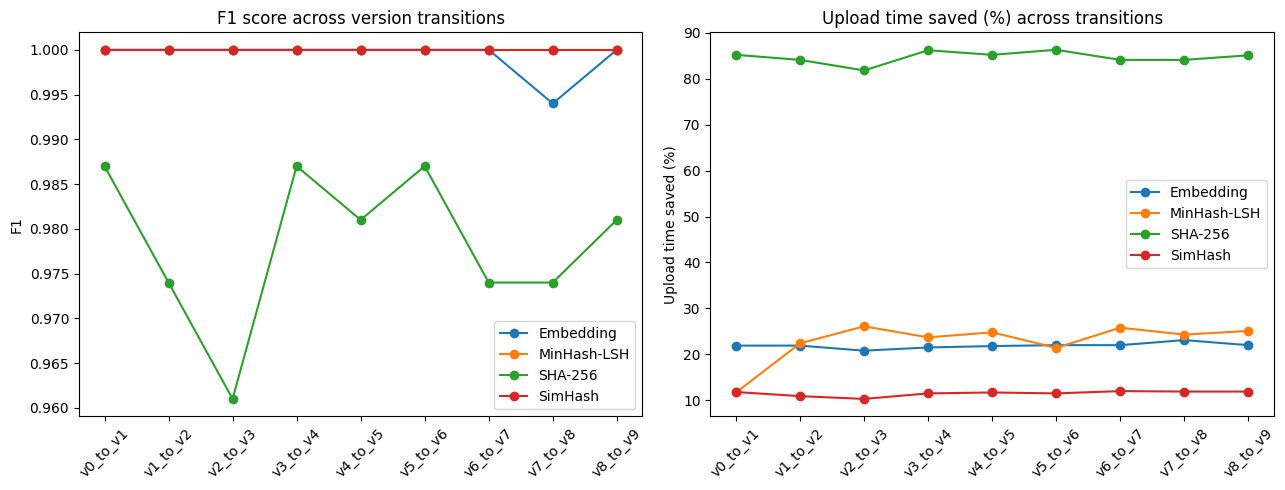

In [ ]:
# STEP 10 — Trend chart: how each algorithm performs across all 9 version transitions
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for algo, g in full_per_transition_df.groupby("algorithm"):
    axes[0].plot(g["transition"], g["f1"], marker="o", label=algo)
    axes[1].plot(g["transition"], g["upload_time_saved_pct"], marker="o", label=algo)

axes[0].set_title("F1 score across version transitions")
axes[0].set_ylabel("F1")
axes[0].legend()
axes[0].tick_params(axis='x', rotation=45)

axes[1].set_title("Upload time saved (%) across transitions")
axes[1].set_ylabel("Upload time saved (%)")
axes[1].legend()
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig("algorithm_comparison_trend.png", dpi=150)
plt.show()

In [ ]:
# CELL 1 — Download Coreutils releases and load their .c/.h source files into memory
import os, io, tarfile, subprocess

CU_RELEASES   = ["8.32", "9.4", "9.5", "9.7"]     # 4 releases -> 3 transitions
CU_DL_DIR     = "coreutils_data"
CU_EXTENSIONS = (".c", ".h")                       # text source files only
CU_MIN_BYTES  = 1000                               # skip tiny files (too few shingles to compare meaningfully)
CU_PATH_PREFIXES = ("src/",)                       # coreutils' own code; add "lib/" for a bigger run (slower)
CU_URLS = [
    "https://ftp.gnu.org/gnu/coreutils/coreutils-{v}.tar.xz",
    "https://ftpmirror.gnu.org/coreutils/coreutils-{v}.tar.xz",   # fallback mirror
]

os.makedirs(CU_DL_DIR, exist_ok=True)
for v in CU_RELEASES:
    path = os.path.join(CU_DL_DIR, f"coreutils-{v}.tar.xz")
    if os.path.exists(path) and os.path.getsize(path) > 100_000:
        continue
    for url in CU_URLS:
        r = subprocess.run(["wget", "-q", "-O", path, url.format(v=v)])
        if r.returncode == 0 and os.path.getsize(path) > 100_000:
            break
    else:
        raise RuntimeError(f"Could not download coreutils-{v}. Swap it for another release in CU_RELEASES.")

cu_files = {}   # version -> {relative_path: bytes}
for v in CU_RELEASES:
    files = {}
    with tarfile.open(os.path.join(CU_DL_DIR, f"coreutils-{v}.tar.xz"), "r:xz") as tf:
        for m in tf.getmembers():
            if not m.isfile() or not m.name.endswith(CU_EXTENSIONS):
                continue
            rel = m.name.split("/", 1)[1] if "/" in m.name else m.name   # drop the "coreutils-X.Y/" prefix
            if not rel.startswith(CU_PATH_PREFIXES):
                continue
            data = tf.extractfile(m).read()
            if len(data) >= CU_MIN_BYTES:
                files[rel] = data
    cu_files[v] = files
    print(f"coreutils-{v}: {len(files)} source files, {sum(map(len, files.values()))/1e6:.1f} MB")

coreutils-8.32: 138 source files, 2.8 MB
coreutils-9.4: 139 source files, 2.9 MB
coreutils-9.5: 139 source files, 2.9 MB
coreutils-9.7: 143 source files, 2.9 MB


In [ ]:
# CELL 2 — Chunking + ground truth (file-path pairing, line-overlap for modified chunks)
import hashlib, random, time, tracemalloc
import numpy as np
import pandas as pd

RANDOM_SEED = 42
CDC_MIN_CHUNK, ENTROPY_WINDOW, ENTROPY_THRESHOLD = 2048, 1024, 4.5
CDC_MASK_LOW_BITS, CDC_MASK_HIGH_BITS = 12, 13
_rng = np.random.RandomState(RANDOM_SEED)
GEAR = [int(x) for x in _rng.randint(0, 2**32 - 1, size=256, dtype=np.int64)]

def shannon_entropy(data):
    if not data:
        return 0.0
    counts = np.bincount(np.frombuffer(data, dtype=np.uint8), minlength=256)
    probs = counts[counts > 0] / len(data)
    return float(-np.sum(probs * np.log2(probs)))

def classify_entropy(h):
    return "low" if h < ENTROPY_THRESHOLD else "high"

def adaptive_chunk(data, entropy_window=ENTROPY_WINDOW):
    n = len(data)
    if n == 0:
        return []
    chunks, start, h, i = [], 0, 0, 0
    local_h = shannon_entropy(data[0:entropy_window])
    bits = CDC_MASK_LOW_BITS if classify_entropy(local_h) == "low" else CDC_MASK_HIGH_BITS
    mask = (1 << bits) - 1
    while i < n:
        h = ((h << 1) + GEAR[data[i]]) & 0xFFFFFFFF
        i += 1
        chunk_len = i - start
        if chunk_len >= CDC_MIN_CHUNK and (h & mask) == 0:
            chunks.append(data[start:i]); start = i
            local_h = shannon_entropy(data[i:i+entropy_window])
            bits = CDC_MASK_LOW_BITS if classify_entropy(local_h) == "low" else CDC_MASK_HIGH_BITS
            mask = (1 << bits) - 1
        elif chunk_len >= 16384:
            chunks.append(data[start:i]); start = i
    if start < n:
        chunks.append(data[start:n])
    return chunks

def sha256_hash(d):
    return hashlib.sha256(d).hexdigest()

def line_set(chunk):
    return {ln.strip() for ln in chunk.decode("utf-8", errors="ignore").splitlines() if ln.strip()}

def line_overlap(b_chunk, a_chunk):
    """Fraction of b_chunk's non-empty lines that also appear in a_chunk.
    This is the ground-truth yardstick: it is independent of MinHash/SimHash/embeddings."""
    lb, la = line_set(b_chunk), line_set(a_chunk)
    return len(lb & la) / len(lb) if lb else 0.0

# ---- ground-truth parameters (adjust here if you want a bigger/smaller run) ----
MODIFIED_MIN_OVERLAP = 0.5    # a changed chunk counts as "modified" if >=50% of its lines exist in the old chunk
UNRELATED_MAX_OVERLAP = 0.3   # a random cross-file pair counts as "unrelated" only if overlap is below this
MAX_IDENTICAL = 100           # identical pairs kept per transition (random sample)
MAX_MODIFIED  = 60            # modified pairs kept per transition (random sample)
N_NEGATIVES   = 30            # unrelated pairs per transition

_chunk_cache = {}
def chunks_of(version, path):
    key = (version, path)
    if key not in _chunk_cache:
        _chunk_cache[key] = adaptive_chunk(cu_files[version][path])
    return _chunk_cache[key]

random.seed(RANDOM_SEED)
cu_rows = []
for a, b in zip(CU_RELEASES[:-1], CU_RELEASES[1:]):
    tname = f"{a}_to_{b}"
    identical, modified, a_chunks_pool = [], [], []
    shared = set(cu_files[a]) & set(cu_files[b])
    for path in sorted(shared):
        ca, cb = chunks_of(a, path), chunks_of(b, path)
        a_chunks_pool.extend(ca)
        a_by_hash = {sha256_hash(c): c for c in ca}
        for c in cb:
            h = sha256_hash(c)
            if h in a_by_hash:
                identical.append((a_by_hash[h], c))
            elif ca:
                best = max(ca, key=lambda x: line_overlap(c, x))
                if line_overlap(c, best) >= MODIFIED_MIN_OVERLAP:
                    modified.append((best, c))      # changed chunk; chunks with no counterpart are skipped
    random.shuffle(identical); random.shuffle(modified)
    for x, y in identical[:MAX_IDENTICAL]:
        cu_rows.append({"transition": tname, "label": "identical", "v0_chunk": x, "v1_chunk": y})
    for x, y in modified[:MAX_MODIFIED]:
        cu_rows.append({"transition": tname, "label": "modified", "v0_chunk": x, "v1_chunk": y})
    # unrelated pairs: random chunk from release a vs random chunk from release b (different content)
    b_pool = [c for p in sorted(shared) for c in chunks_of(b, p)]
    made, tries = 0, 0
    while made < N_NEGATIVES and tries < 2000:
        tries += 1
        x, y = random.choice(a_chunks_pool), random.choice(b_pool)
        if line_overlap(y, x) < UNRELATED_MAX_OVERLAP:
            cu_rows.append({"transition": tname, "label": "unrelated", "v0_chunk": x, "v1_chunk": y})
            made += 1

cu_eval_df = pd.DataFrame(cu_rows)
cu_eval_df["is_true_dup"] = cu_eval_df["label"].isin(["identical", "modified"])
print("Total pairs:", len(cu_eval_df))
print(cu_eval_df.groupby(["transition", "label"]).size().unstack(fill_value=0))
print("Mean chunk size (bytes):", int(cu_eval_df["v1_chunk"].apply(len).mean()))


Total pairs: 479
label        identical  modified  unrelated
transition                                 
8.32_to_9.4         24        60         30
9.4_to_9.5         100        60         30
9.5_to_9.7          85        60         30
Mean chunk size (bytes): 7485


In [ ]:
!pip install datasketch sentence-transformers -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.2/107.2 kB 3.1 MB/s eta 0:00:00


In [ ]:
# CELL 3 — The four detection methods (same settings as the first dataset)
from datasketch import MinHash

SHINGLE_SIZE, MINHASH_PERM, MINHASH_JACCARD_THRESH = 5, 128, 0.5
SIMHASH_BITS, SIMHASH_HAMMING_THRESH = 64, 6
COSINE_THRESH = 0.85
USE_EMBEDDING = True          # set False to skip the embedding model (faster, no download)

def create_shingles(text, k=SHINGLE_SIZE):
    words = text.split()
    if len(words) < k:
        return {" ".join(words)} if words else set()
    return {" ".join(words[i:i+k]) for i in range(len(words) - k + 1)}

def minhash_signature(shingles, num_perm=MINHASH_PERM):
    m = MinHash(num_perm=num_perm, seed=42)
    for s in shingles:
        m.update(s.encode("utf-8"))
    return m

def sha256_predict(a, b):
    return "duplicate" if sha256_hash(a) == sha256_hash(b) else "new"

def minhash_predict(a, b):
    ta, tb = a.decode("utf-8", errors="ignore"), b.decode("utf-8", errors="ignore")
    m0, m1 = minhash_signature(create_shingles(ta)), minhash_signature(create_shingles(tb))
    return "duplicate" if m0.jaccard(m1) >= MINHASH_JACCARD_THRESH else "new"

def simhash_fingerprint(text, bits=SIMHASH_BITS):
    weights = [0] * bits
    for shingle in (create_shingles(text, k=2) or {text}):
        h = int(hashlib.md5(shingle.encode("utf-8")).hexdigest(), 16)
        for i in range(bits):
            weights[i] += 1 if (h >> i) & 1 else -1
    fp = 0
    for i in range(bits):
        if weights[i] > 0:
            fp |= (1 << i)
    return fp

def hamming_distance(x, y):
    return bin(x ^ y).count("1")

def simhash_predict(a, b):
    ta, tb = a.decode("utf-8", errors="ignore"), b.decode("utf-8", errors="ignore")
    return "duplicate" if hamming_distance(simhash_fingerprint(ta), simhash_fingerprint(tb)) <= SIMHASH_HAMMING_THRESH else "new"

CU_ALGORITHMS = {"SHA-256": sha256_predict, "MinHash-LSH": minhash_predict, "SimHash": simhash_predict}

if USE_EMBEDDING:
    try:
        from sentence_transformers import SentenceTransformer
    except ImportError:
        import subprocess, sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sentence-transformers"], check=True)
        from sentence_transformers import SentenceTransformer
    embed_model = SentenceTransformer("all-MiniLM-L6-v2")

    def embedding_predict(a, b):
        ta, tb = a.decode("utf-8", errors="ignore")[:2000], b.decode("utf-8", errors="ignore")[:2000]
        e = embed_model.encode([ta, tb])
        sim = float(np.dot(e[0], e[1]) / (np.linalg.norm(e[0]) * np.linalg.norm(e[1])))
        return "duplicate" if sim >= COSINE_THRESH else "new"

    CU_ALGORITHMS["Embedding"] = embedding_predict

print("Methods ready:", list(CU_ALGORITHMS))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Methods ready: ['SHA-256', 'MinHash-LSH', 'SimHash', 'Embedding']


In [ ]:
# CELL 4 — Run every method on every transition (full metrics, same definitions as before)
NETWORK_DELAY = 0.1

def evaluate_full(name, predict_fn, sub_df):
    tracemalloc.start()
    t0 = time.perf_counter()
    preds = [predict_fn(r["v0_chunk"], r["v1_chunk"]) for _, r in sub_df.iterrows()]
    elapsed = time.perf_counter() - t0
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    actual = sub_df["is_true_dup"]
    pred = pd.Series(preds, index=sub_df.index) != "new"
    tp, fp = int((actual & pred).sum()), int((~actual & pred).sum())
    fn, tn = int((actual & ~pred).sum()), int((~actual & ~pred).sum())
    precision = tp / (tp + fp) if (tp + fp) else float("nan")
    recall = tp / (tp + fn) if (tp + fn) else float("nan")
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else float("nan")
    accuracy = (tp + tn) / len(sub_df)

    sizes = sub_df["v1_chunk"].apply(len)
    original = int(sizes.sum())
    transferred = int(sizes[~pred].sum())
    dedup_ratio = original / transferred if transferred else float("inf")
    saved_pct = (1 - transferred / original) * 100 if original else 0

    n_pairs = len(sub_df)
    n_sent = n_pairs - int(pred.sum())
    naive_time = elapsed + n_pairs * NETWORK_DELAY
    upload_time = elapsed + n_sent * NETWORK_DELAY
    return {
        "transition": sub_df["transition"].iloc[0], "algorithm": name,
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "precision": round(precision, 3), "recall": round(recall, 3),
        "f1": round(f1, 3), "accuracy": round(accuracy, 3),
        "processing_time_s": round(elapsed, 4), "memory_kb": round(peak / 1024, 1),
        "duplicate_chunks_detected": int(pred.sum()),
        "dedup_ratio": round(dedup_ratio, 2), "storage_saved_pct": round(saved_pct, 1),
        "data_transferred_bytes": transferred, "bandwidth_saved_pct": round(saved_pct, 1),
        "upload_time_s": round(upload_time, 3),
        "upload_time_saved_pct": round((1 - upload_time / naive_time) * 100, 1),
    }

cu_rows_out = []
for transition, sub_df in cu_eval_df.groupby("transition", sort=False):
    for algo, fn_ in CU_ALGORITHMS.items():
        print(f"{transition} | {algo} ...", end=" ", flush=True)
        cu_rows_out.append(evaluate_full(algo, fn_, sub_df))
        print("done")

cu_results_df = pd.DataFrame(cu_rows_out)
cu_results_df.to_csv("coreutils_results.csv", index=False)
cu_results_df

8.32_to_9.4 | SHA-256 ... done
8.32_to_9.4 | MinHash-LSH ... done
8.32_to_9.4 | SimHash ... done
8.32_to_9.4 | Embedding ... done
9.4_to_9.5 | SHA-256 ... done
9.4_to_9.5 | MinHash-LSH ... done
9.4_to_9.5 | SimHash ... done
9.4_to_9.5 | Embedding ... done
9.5_to_9.7 | SHA-256 ... done
9.5_to_9.7 | MinHash-LSH ... done
9.5_to_9.7 | SimHash ... done
9.5_to_9.7 | Embedding ... done


,transition,algorithm,TP,FP,FN,TN,precision,recall,f1,accuracy,processing_time_s,memory_kb,duplicate_chunks_detected,dedup_ratio,storage_saved_pct,data_transferred_bytes,bandwidth_saved_pct,upload_time_s,upload_time_saved_pct
0,8.32_to_9.4,SHA-256,24,0,60,30,1.0,0.286,0.444,0.474,0.1210,10.7,24,1.16,13.7,779625,13.7,9.121,20.8
1,8.32_to_9.4,MinHash-LSH,71,0,13,30,1.0,0.845,0.916,0.886,46.9148,452.6,71,2.54,60.7,355358,60.7,51.215,12.2
2,8.32_to_9.4,SimHash,48,0,36,30,1.0,0.571,0.727,0.684,34.5699,385.1,48,1.59,37.0,568930,37.0,41.170,10.4
3,8.32_to_9.4,Embedding,74,0,10,30,1.0,0.881,0.937,0.912,27.4257,221.8,74,2.61,61.7,345700,61.7,31.426,19.1
4,9.4_to_9.5,SHA-256,100,0,60,30,1.0,0.625,0.769,0.684,0.0415,16.6,100,1.87,46.5,744854,46.5,9.042,52.5
5,9.4_to_9.5,MinHash-LSH,160,0,0,30,1.0,1.000,1.000,1.000,26.1348,447.2,160,6.67,85.0,208743,85.0,29.135,35.4
6,9.4_to_9.5,SimHash,147,0,13,30,1.0,0.919,0.958,0.932,59.3545,384.0,147,4.01,75.1,347198,75.1,63.655,18.8
7,9.4_to_9.5,Embedding,158,0,2,30,1.0,0.988,0.994,0.989,45.2168,291.8,158,6.03,83.4,230750,83.4,48.417,24.6
8,9.5_to_9.7,SHA-256,85,0,60,30,1.0,0.586,0.739,0.657,0.0397,15.4,85,1.61,37.9,800096,37.9,9.040,48.5
9,9.5_to_9.7,MinHash-LSH,145,0,0,30,1.0,1.000,1.000,1.000,22.8027,457.8,145,4.45,77.5,289535,77.5,25.803,36.0


             F1_min  F1_mean  recall_mean  precision_mean  time_s  memory_kb  \
algorithm                                                                      
Embedding     0.937    0.975        0.952             1.0  37.879    202.433   
MinHash-LSH   0.916    0.972        0.948             1.0  31.951    452.533   
SHA-256       0.444    0.651        0.499             1.0   0.067     14.233   
SimHash       0.727    0.886        0.812             1.0  46.585    389.267   

             bandwidth_saved_pct  upload_time_saved_pct  
algorithm                                                
Embedding                 73.433                 22.700  
MinHash-LSH               74.400                 27.867  
SHA-256                   32.700                 40.600  
SimHash                   61.400                 16.933  


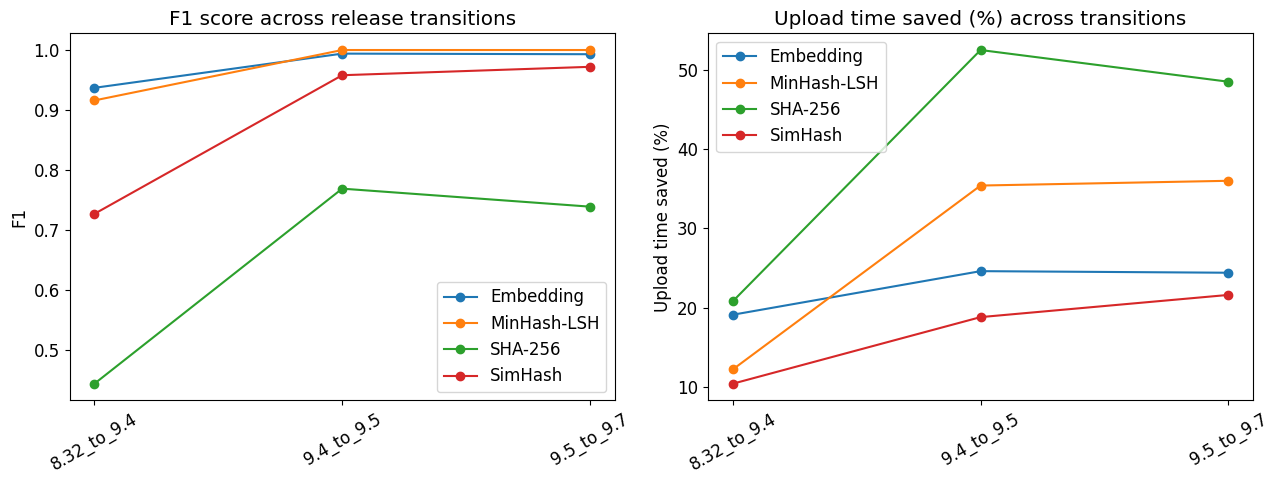

In [ ]:
# CELL 5 — Summary table + trend charts for the Coreutils dataset
import matplotlib.pyplot as plt

summary = (cu_results_df.groupby("algorithm")
           .agg(F1_min=("f1", "min"), F1_mean=("f1", "mean"),
                recall_mean=("recall", "mean"), precision_mean=("precision", "mean"),
                time_s=("processing_time_s", "mean"), memory_kb=("memory_kb", "mean"),
                bandwidth_saved_pct=("bandwidth_saved_pct", "mean"),
                upload_time_saved_pct=("upload_time_saved_pct", "mean"))
           .round(3))
print(summary)
summary.to_csv("coreutils_summary.csv")

plt.rcParams.update({"font.size": 12})
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for algo, g in cu_results_df.groupby("algorithm"):
    axes[0].plot(g["transition"], g["f1"], marker="o", label=algo)
    axes[1].plot(g["transition"], g["upload_time_saved_pct"], marker="o", label=algo)
axes[0].set_title("F1 score across release transitions"); axes[0].set_ylabel("F1")
axes[1].set_title("Upload time saved (%) across transitions"); axes[1].set_ylabel("Upload time saved (%)")
for ax in axes:
    ax.legend(); ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig("coreutils_trend.png", dpi=300)
plt.show()